# AOP-ProCon — Step 8: Confound controls (source, length, split design, data size)

Following the assessment `C1_Assessment_2026-10-18.md` (Tier A items 1–3) and `found_errors.md` **N-19**, this notebook tests whether the "mechanism signal" of the ESM-2 probe is really caused by **source** (AnOxPePred vs external literature) or by **length**. No contrastive model is trained here — only frozen features and logistic-regression probes.

**Pool:** `strict` (`strict_evidence == True`), n = 669: MC-active 104 (MC-only 18 + FRS;MC 86) vs FRS-only 565. Target `y = 1` if `labels` contains `MC`.

| § | Analysis | Output |
|---|---|---|
| 1 | Split design: `StratifiedGroupKFold(5)` × 10 repeats on `homology_group` (cluster fallback for unresolvable rows) vs the old `GroupKFold(5)` and the 2-fold `lso_fold` | `step8_cv_design.csv`, `step8_fold_composition.csv` |
| 2 | Strict-pool probes: SOURCE-only, LENGTH-only, AAC-20, DESC-14, AAC+LEN+SRC, ESM-2 35M/150M/650M/3B, noise | `step8_probe_strict.csv` |
| 3 | AnOxPePred-only subset (75 MC vs 565 FRS — one source) | `step8_probe_anoxpepred_only.csv` |
| 4 | Length-matched subsampling (20 draws), strict and AnOxPePred-only | `step8_length_matched.csv`, `step8_length_matched_runs.csv` |
| 5 | Learning curve, 25 / 50 / 75 / 100 % of each training fold | `step8_learning_curve.csv`, `step8_learning_curve.png` |
| 6 | ΔAUROC of adding ESM-2 on top of AAC+LEN(+SRC), paired | `step8_delta_esm_over_confounds.csv` |

**Statistics.** Same probe as Step 5 (`StandardScaler` inside the training fold, `LogisticRegression(C=1, class_weight="balanced")`). The headline `AUROC` is the **fold-mean AUROC** — the mean of the 50 per-fold test AUROCs (5 folds × 10 repeats). Its 95 % CI is a **group bootstrap over homology groups** (2000 resamples, whole groups resampled because peptides of one group are not independent; each resample re-weights the test peptides of every fold and recomputes all 50 fold AUROCs). ΔAUROC is paired (same folds, same bootstrap resamples).

*Why not pooled OOF AUROC (Step 5's headline)?* Pooling OOF scores from different folds mixes five separately-fitted intercepts, and that offset alone moves the AUROC: SOURCE-only, a single binary feature whose exact AUROC is 0.639, gets a pooled OOF AUROC of ≈ 0.48–0.54, and pure noise gets 0.38 in Step 5. The pooled AUROC of the repeat-averaged score (`AUROC_pooled`) is kept as a secondary column only.

*Chance reference.* The single 64-d noise matrix of Step 5 (`RandomState(0)`, kept here as `RANDOM noise (seed 0)`) happens to score ≈ 0.39, about 3 sd below its own null mean; over 20 other noise draws the fold-mean AUROC is ≈ 0.49–0.50. The **NULL band** row (mean and 2.5–97.5 % over 20 noise seeds) is therefore the chance reference, and `above_null_97_5` flags feature sets above it.

*What the CIs do and do not cover.* The group bootstrap resamples the test peptides with the fitted models held fixed; it does not include refitting variance. It is therefore narrower than the true uncertainty (the seed-0 noise CI excludes 0.5). Read it together with the NULL band, the repeat range (`AUROC_rep_min/max`) and, for differences, the number of repeats in which the difference has the same sign.

## 0. Setup — paths (Colab or local), zip extraction, integrity checks

In [1]:
import os, sys, json, math, hashlib, zipfile, datetime, warnings
from importlib import metadata

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/AOP-ProCon"
    REL  = f"{BASE}/release/aop_procon_v1"          # release package written by STEP07
    OUT  = f"{BASE}/results/step8"
    ZIP  = os.environ.get("AOP8_ZIP")               # optional: a Drive-exported zip of AOP-ProCon/
    SCRATCH = "/content/aop8"
else:
    # Local Windows run: the zip's internal paths are too long for the OneDrive folder, so extract to a short path.
    ZIP     = os.environ.get("AOP8_ZIP", r"D:\Download\AOP-ProCon-20261018T090203Z-1-001.zip")
    SCRATCH = os.environ.get("AOP8_SCRATCH", os.path.join(os.environ.get("TEMP", "/tmp"), "aop8"))
    REL     = os.path.join(SCRATCH, "AOP-ProCon", "release", "aop_procon_v1")
    OUT     = os.environ.get("AOP8_OUT", os.path.abspath("."))   # = C1/STEP 08 when run from the notebook's folder

SCALES = ["35M", "150M", "650M", "3B"]
NEEDED = (["MANIFEST.json", "data/AOP-BenchPos_S2.csv", "data/descriptors.csv"]
          + [f"embeddings/esm2_{s}.npy" for s in SCALES] + [f"embeddings/esm2_{s}_sequences.txt" for s in SCALES])

missing = [f for f in NEEDED if not os.path.exists(os.path.join(REL, f))]
if missing:
    assert ZIP and os.path.exists(ZIP), f"release files missing under {REL} and no zip to extract from: {missing}"
    prefix = "AOP-ProCon/release/aop_procon_v1/"
    with zipfile.ZipFile(ZIP) as z:
        names = set(z.namelist())
        for f in missing:
            member = prefix + f
            assert member in names and ".." not in member, f"{member} not in zip"
            z.extract(member, SCRATCH)
    print(f"extracted {len(missing)} files from {os.path.basename(ZIP)} -> {SCRATCH}")
os.makedirs(OUT, exist_ok=True)
print("IN_COLAB:", IN_COLAB, "\nREL :", REL, "\nOUT :", OUT)

IN_COLAB: False 
REL : C:\Users\angel\AppData\Local\Temp\aop8\AOP-ProCon\release\aop_procon_v1 
OUT : C:\Users\angel\OneDrive - Sri Lanka Institute of Information Technology\Desktop\Research\my\C1\STEP 08


In [2]:
import numpy as np, pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold, GroupKFold
from sklearn.exceptions import ConvergenceWarning
import matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)

SEED = 42; N_BOOT = 2000; N_SPLITS = 5; N_REPEATS = 10
N_MATCH_DRAWS = 20; MATCH_REPEATS = 2; LC_FRACS = [0.25, 0.50, 0.75, 1.00]

def _ver(p):
    try: return metadata.version(p)
    except Exception: return "n/a"
VERSIONS = {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__,
            "scikit-learn": _ver("scikit-learn"), "matplotlib": matplotlib.__version__}
print(VERSIONS)

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""): h.update(chunk)
    return h.hexdigest()

def s2_fingerprint(s2_df):                                    # identical to STEP05
    lines = []
    for r in s2_df.sort_values("sequence").itertuples():
        lines.append("\t".join([r.sequence, r.labels,
                                "" if pd.isna(r.homology_group) else str(int(r.homology_group)),
                                "" if pd.isna(r.lso_fold) else str(int(r.lso_fold)),
                                f"{float(r.sample_weight):.1f}"]))
    return hashlib.md5("\n".join(lines).encode()).hexdigest()[:16]

MANIFEST = json.load(open(os.path.join(REL, "MANIFEST.json"), encoding="utf-8"))
HASHES = {}
for f in NEEDED[1:]:
    if f.endswith(".txt"): continue                            # sequence lists are not hashed in the MANIFEST
    HASHES[f] = sha256_file(os.path.join(REL, f))
    assert HASHES[f] == MANIFEST["files"][f], f"SHA-256 mismatch: {f}"
S2 = pd.read_csv(os.path.join(REL, "data/AOP-BenchPos_S2.csv"))
FP = s2_fingerprint(S2)
assert FP == MANIFEST["s2_fingerprint"] == "47d9c2a2fff63eb1", FP
print(f"SHA-256 OK for {len(HASHES)} files; S2 fingerprint {FP}")

{'python': '3.12.6', 'numpy': '2.5.4', 'pandas': '3.0.6', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.2'}
SHA-256 OK for 6 files; S2 fingerprint 47d9c2a2fff63eb1


## 1. Strict pool, groups, features

In [3]:
d = S2[S2["strict_evidence"] == True].reset_index(drop=True).copy()
d["y"] = d["labels"].str.contains("MC").astype(int)
d["is_external"] = (d["source_group"] == "external_literature").astype(int)
assert len(d) == 669 and d["y"].sum() == 104 and (d["y"] == 0).sum() == 565

# Groups: homology_group (STEP01: cluster_40 + identical sequence + >=70 %-identity links, union-find).
# Tripeptides are "unresolvable" (homology_resolvable == False) but STEP01 already gives them their cluster_40-based group;
# any row still without a homology_group falls back to its own cluster_40 id (kept in a separate id space).
n_nan = int(d["homology_group"].isna().sum())
d["group"] = np.where(d["homology_group"].notna(), "hg_" + d["homology_group"].astype("Int64").astype(str),
                      "c40_" + d["cluster_40"].astype(str))
print(f"n={len(d)}  MC-active={d.y.sum()} (MC-only {(d.labels=='MC').sum()}, FRS;MC {(d.labels=='FRS;MC').sum()})  FRS-only={(d.y==0).sum()}")
print(f"homology groups={d.group.nunique()}  rows without homology_group (cluster fallback)={n_nan}  "
      f"unresolvable rows={(~d.homology_resolvable).sum()} (all length {sorted(d.loc[~d.homology_resolvable,'length'].unique())})")
print("\nsource x label:"); print(pd.crosstab(d["labels"], d["source_group"], margins=True))
print("\nlength by class:"); print(d.groupby("y")["length"].describe().round(2))
print(f"share of tripeptides: FRS-only {np.mean(d.loc[d.y==0,'length']==3):.1%}  MC-active {np.mean(d.loc[d.y==1,'length']==3):.1%}")

n=669  MC-active=104 (MC-only 18, FRS;MC 86)  FRS-only=565
homology groups=541  rows without homology_group (cluster fallback)=0  unresolvable rows=259 (all length [np.int64(3)])

source x label:
source_group  AnOxPePred  external_literature  All
labels                                            
FRS                  565                    0  565
FRS;MC                66                   20   86
MC                     9                    9   18
All                  640                   29  669

length by class:
   count  mean   std  min  25%  50%  75%   max
y                                             
0  565.0  5.75  4.50  3.0  3.0  4.0  6.0  36.0
1  104.0  5.86  3.45  3.0  4.0  5.0  7.0  22.0
share of tripeptides: FRS-only 42.8%  MC-active 16.3%


In [4]:
AA = "ACDEFGHIKLMNPQRSTVWY"
assert set("".join(d["sequence"])) <= set(AA)
def aac(s): return np.array([s.count(a) / len(s) for a in AA])

DESC = pd.read_csv(os.path.join(REL, "data/descriptors.csv")).set_index("sequence")
ESM = {}
for sc in SCALES:
    X = np.load(os.path.join(REL, f"embeddings/esm2_{sc}.npy"))
    seqs = open(os.path.join(REL, f"embeddings/esm2_{sc}_sequences.txt"), encoding="utf-8").read().split()
    assert X.shape[0] == len(seqs) == len(set(seqs)) and np.isfinite(X).all()
    idx = {s: i for i, s in enumerate(seqs)}
    ESM[sc] = X[[idx[s] for s in d["sequence"]]]
    print(f"ESM-2 {sc}: {ESM[sc].shape}")

F = {}
F["SOURCE"]  = d[["is_external"]].values.astype(float)
F["LENGTH"]  = np.c_[d["length"].values, np.log(d["length"].values)].astype(float)      # same as STEP05
F["AAC-20"]  = np.stack([aac(s) for s in d["sequence"]])
F["DESC-14"] = DESC.loc[d["sequence"]].values.astype(float)
F["AAC+LEN"] = np.hstack([F["AAC-20"], F["LENGTH"]])
F["AAC+LEN+SRC"] = np.hstack([F["AAC+LEN"], F["SOURCE"]])
for sc in SCALES:
    F[f"ESM-2 {sc}"] = ESM[sc]
    F[f"ESM-2 {sc} + AAC+LEN"] = np.hstack([ESM[sc], F["AAC+LEN"]])
    F[f"ESM-2 {sc} + AAC+LEN+SRC"] = np.hstack([ESM[sc], F["AAC+LEN+SRC"]])
F["RANDOM noise"] = np.random.RandomState(0).normal(size=(len(d), 64))
y_all = d["y"].values; g_all = d["group"].values
print({k: v.shape[1] for k, v in F.items()})

ESM-2 35M: (669, 480)
ESM-2 150M: (669, 640)
ESM-2 650M: (669, 1280)
ESM-2 3B: (669, 2560)
{'SOURCE': 1, 'LENGTH': 2, 'AAC-20': 20, 'DESC-14': 14, 'AAC+LEN': 22, 'AAC+LEN+SRC': 23, 'ESM-2 35M': 480, 'ESM-2 35M + AAC+LEN': 502, 'ESM-2 35M + AAC+LEN+SRC': 503, 'ESM-2 150M': 640, 'ESM-2 150M + AAC+LEN': 662, 'ESM-2 150M + AAC+LEN+SRC': 663, 'ESM-2 650M': 1280, 'ESM-2 650M + AAC+LEN': 1302, 'ESM-2 650M + AAC+LEN+SRC': 1303, 'ESM-2 3B': 2560, 'ESM-2 3B + AAC+LEN': 2582, 'ESM-2 3B + AAC+LEN+SRC': 2583, 'RANDOM noise': 64}


## 2. CV engine and statistics

* `make_splits` → `StratifiedGroupKFold(5, shuffle=True, random_state=SEED + r)` for r = 0…9. The folds depend only on (y, groups), so **every feature set sees exactly the same folds** → paired comparisons are valid.
* `train_frac < 1` (learning curve): the training fold is subsampled **by homology group**, stratified by whether the group contains an MC-active peptide; the test fold is unchanged.
* `boot_weights` draws the group bootstrap once per pool (2000 × multinomial counts over homology groups); `wauc` is a weighted AUROC, so every resample recomputes all 50 fold AUROCs exactly.

In [5]:
def make_splits(y, g, n_repeats=N_REPEATS, seed=SEED):
    dummy = np.zeros(len(y))
    return [list(StratifiedGroupKFold(N_SPLITS, shuffle=True, random_state=seed + r).split(dummy, y, g)) for r in range(n_repeats)]

def fit_predict(Xtr, ytr, Xte):
    sc = StandardScaler().fit(Xtr)
    clf = LogisticRegression(max_iter=3000, C=1.0, class_weight="balanced").fit(sc.transform(Xtr), ytr)
    return clf.predict_proba(sc.transform(Xte))[:, 1]

def subsample_groups(tr, y, g, frac, rng):
    # keep `frac` of the training groups, stratified by "group has an MC-active member"
    gt = pd.DataFrame({"i": tr, "g": g[tr], "y": y[tr]})
    gy = gt.groupby("g")["y"].max()
    keep = []
    for cls in (0, 1):
        gs = gy.index[gy.values == cls].to_numpy()
        n = max(1, int(round(frac * len(gs))))
        keep.extend(rng.choice(gs, n, replace=False))
    return gt.loc[gt["g"].isin(set(keep)), "i"].to_numpy()

def run_cv(X, y, g, splits, train_frac=1.0, seed=SEED):
    R = len(splits); oof = np.full((R, len(y)), np.nan); fold_auc = np.full((R, N_SPLITS), np.nan)
    for r, folds in enumerate(splits):
        for k, (tr, te) in enumerate(folds):
            if train_frac < 1:
                tr = subsample_groups(tr, y, g, train_frac, np.random.RandomState(seed + 1000 * r + k))
            oof[r, te] = fit_predict(X[tr], y[tr], X[te])
            if len(set(y[te])) > 1: fold_auc[r, k] = roc_auc_score(y[te], oof[r, te])
    assert np.isfinite(oof).all()
    return oof, fold_auc

def boot_weights(g, n=N_BOOT, seed=0):
    # group bootstrap as multiplicity weights: (n, n_samples); every peptide inherits its homology group's draw count
    u, inv = np.unique(g, return_inverse=True)
    c = np.random.RandomState(seed).multinomial(len(u), np.full(len(u), 1 / len(u)), size=n)
    return c[:, inv].astype(float)

def wauc(s, y, W):
    # weighted AUROC (ties = 1/2) for every row of W; NaN where a resample has no positive or no negative weight
    u, inv = np.unique(s, return_inverse=True); O = np.zeros((len(s), len(u))); O[np.arange(len(s)), inv] = 1
    P, N = (W * y) @ O, (W * (1 - y)) @ O
    num = (P * (np.cumsum(N, 1) - N + 0.5 * N)).sum(1); den = P.sum(1) * N.sum(1)
    return np.where(den > 0, num / np.where(den > 0, den, 1), np.nan)

def boot_foldmean(oof, y, splits, W):
    # bootstrap distribution of the fold-mean AUROC (same resamples W for every feature set -> paired)
    acc = [wauc(oof[r, te], y[te], W[:, te]) for r, folds in enumerate(splits) for _, te in folds]
    return np.nanmean(np.stack(acc, 1), 1)

_t = np.random.RandomState(1); _s, _y = _t.rand(50).round(1), _t.randint(0, 2, 50)
assert abs(wauc(_s, _y, np.ones((1, 50)))[0] - roc_auc_score(_y, _s)) < 1e-12        # wauc == sklearn on unit weights

def summarise(name, X, y, g, oof, fold_auc, splits, W):
    rep_fm = np.nanmean(fold_auc, 1); rep_pool = np.array([roc_auc_score(y, o) for o in oof])
    b = boot_foldmean(oof, y, splits, W); lo, hi = np.percentile(b, [2.5, 97.5])
    return {"features": name, "dim": X.shape[1], "n": len(y), "n_MC": int(y.sum()), "n_groups": len(np.unique(g)),
            "AUROC": np.nanmean(fold_auc), "lo": lo, "hi": hi,
            "AUROC_rep_sd": rep_fm.std(ddof=1), "AUROC_rep_min": rep_fm.min(), "AUROC_rep_max": rep_fm.max(),
            "AUROC_pooled": roc_auc_score(y, oof.mean(0)), "AUROC_pooled_rep_mean": rep_pool.mean()}

N_NULL_SEEDS = 20
def null_band(y, g, splits, dim=64, n_seeds=N_NULL_SEEDS):
    # empirical null: fold-mean AUROC of pure-noise features over many noise draws (the fixed seed-0 draw used by Step 5
    # happens to sit ~3 sd low, so a single noise row is not a usable chance reference)
    vals = []
    for s in range(n_seeds):
        X = np.random.RandomState(1000 + s).normal(size=(len(y), dim))
        vals.append(np.nanmean(run_cv(X, y, g, splits)[1]))
    vals = np.array(vals)
    return {"features": f"NULL band: RANDOM noise {dim}-d, {n_seeds} seeds", "dim": dim, "n": len(y), "n_MC": int(y.sum()),
            "n_groups": len(np.unique(g)), "AUROC": vals.mean(), "lo": np.percentile(vals, 2.5), "hi": np.percentile(vals, 97.5),
            "AUROC_rep_sd": vals.std(ddof=1), "AUROC_rep_min": vals.min(), "AUROC_rep_max": vals.max()}

def paired_delta(name_a, name_b, y, splits, W, OOFd, FAd, context):
    dlt = boot_foldmean(OOFd[name_a], y, splits, W) - boot_foldmean(OOFd[name_b], y, splits, W)
    a, b = np.nanmean(FAd[name_a]), np.nanmean(FAd[name_b])
    rep = np.nanmean(FAd[name_a], 1) - np.nanmean(FAd[name_b], 1)
    p = min(1.0, 2 * min((dlt <= 0).mean(), (dlt >= 0).mean()))
    lo, hi = np.percentile(dlt, [2.5, 97.5])
    return {"context": context, "model": name_a, "reference": name_b, "AUROC_model": a, "AUROC_reference": b,
            "delta_AUROC": a - b, "lo": lo, "hi": hi, "p_boot_two_sided": p,
            "delta_rep_mean": rep.mean(), "delta_rep_min": rep.min(), "delta_rep_max": rep.max(),
            "repeats_delta_gt_0": int((rep > 0).sum()), "n": len(y), "n_MC": int(y.sum()),
            "verdict": ("model better" if lo > 0 else "reference better" if hi < 0 else "no difference detected")}

## 3. Split design (assessment item 2)

The retrieval protocol (Step 5/6) uses the 2-fold `lso_fold` split, in which **all 18 MC-only peptides fall in fold 1**. The Step 5 probe used `GroupKFold(5)` (deterministic, not stratified, one repeat). Here: how the MC-active / MC-only peptides spread over folds under each design, and how much one split moves the ESM-2 650M AUROC.

In [6]:
SPLITS = make_splits(y_all, g_all)
comp = []
lso = d["lso_fold"].values
for f in (0, 1):
    m = lso == f
    comp.append({"design": "lso_fold 2-fold (Step 5 retrieval)", "repeat": 0, "fold": f, "n": int(m.sum()),
                 "MC_active": int(d.y[m].sum()), "MC_only": int((d.labels[m] == "MC").sum()), "external": int(d.is_external[m].sum())})
for k, (_, te) in enumerate(GroupKFold(N_SPLITS).split(F["AAC-20"], y_all, g_all)):
    comp.append({"design": "GroupKFold(5) (Step 5 probe)", "repeat": 0, "fold": k, "n": len(te), "MC_active": int(y_all[te].sum()),
                 "MC_only": int((d.labels.values[te] == "MC").sum()), "external": int(d.is_external.values[te].sum())})
for r, folds in enumerate(SPLITS):
    for k, (tr, te) in enumerate(folds):
        assert not set(g_all[tr]) & set(g_all[te]), "a homology group spans train and test"
        comp.append({"design": "StratifiedGroupKFold(5) x10 (Step 8)", "repeat": r, "fold": k, "n": len(te), "MC_active": int(y_all[te].sum()),
                     "MC_only": int((d.labels.values[te] == "MC").sum()), "external": int(d.is_external.values[te].sum())})
COMP = pd.DataFrame(comp); COMP.to_csv(f"{OUT}/step8_fold_composition.csv", index=False)
print(COMP.groupby("design")[["n", "MC_active", "MC_only", "external"]].agg(["min", "max"]))

# The released Step 5 number is reproduced exactly from its own OOF scores ...
REL_OOF = pd.read_csv(os.path.join(REL, "data/oof_probe_scores.csv")).set_index("sequence").loc[d["sequence"], "oof_mc_score_strict"].values
auc_rel = roc_auc_score(y_all, REL_OOF)
assert abs(auc_rel - MANIFEST["probes"]["strict"]["grouped_cv_auroc_esm650M"]) < 1e-6
print(f"Step 5 released OOF (oof_probe_scores.csv), ESM-2 650M strict: pooled AUROC = {auc_rel:.4f}  (MANIFEST {MANIFEST['probes']['strict']['grouped_cv_auroc_esm650M']})")

# ... but re-running the same GroupKFold(5) recipe gives a different single split (GroupKFold breaks ties between equal-size
# groups by the order of the group ids, and that order changed between scikit-learn releases). Every row below is one design.
def design_row(name, design, oof, fold_aucs):
    return {"features": name, "design": design, "AUROC_pooled": roc_auc_score(y_all, oof) if oof is not None else np.nan,
            "AUROC_foldmean": np.nanmean(fold_aucs)}
g_int = d["homology_group"].values.astype(int)                 # Step 5 used the integer ids
rows = [{"features": "ESM-2 650M", "design": "Step 5 released OOF (scikit-learn 1.6.1)", "AUROC_pooled": auc_rel, "AUROC_foldmean": np.nan}]
for name in ("ESM-2 650M", "AAC-20", "SOURCE", "LENGTH"):
    X = F[name]
    for tr_f, te_f in ((0, 1), (1, 0)):
        tr, te = np.flatnonzero(lso == tr_f), np.flatnonzero(lso == te_f)
        a = roc_auc_score(y_all[te], fit_predict(X[tr], y_all[tr], X[te]))
        rows.append({"features": name, "design": f"lso_fold 2-fold, train {tr_f} -> test {te_f}", "AUROC_pooled": a, "AUROC_foldmean": a})
    for gname, gg in (("integer ids", g_int), ("string ids", g_all)):
        oof = np.full(len(y_all), np.nan); fa = []
        for tr, te in GroupKFold(N_SPLITS).split(X, y_all, gg):
            oof[te] = fit_predict(X[tr], y_all[tr], X[te]); fa.append(roc_auc_score(y_all[te], oof[te]))
        rows.append(design_row(name, f"GroupKFold(5) re-run, {gname} (scikit-learn {VERSIONS['scikit-learn']})", oof, fa))
    o, fa = run_cv(X, y_all, g_all, SPLITS)
    fm = np.nanmean(fa, 1); pooled = np.array([roc_auc_score(y_all, oo) for oo in o])
    rows.append({"features": name, "design": "StratifiedGroupKFold(5) x10: lowest repeat", "AUROC_pooled": pooled.min(), "AUROC_foldmean": fm.min()})
    rows.append({"features": name, "design": "StratifiedGroupKFold(5) x10: highest repeat", "AUROC_pooled": pooled.max(), "AUROC_foldmean": fm.max()})
    rows.append(design_row(name, "StratifiedGroupKFold(5) x10: all 50 folds (Step 8 headline = AUROC_foldmean)", o.mean(0), fa))
CVD = pd.DataFrame(rows); CVD.to_csv(f"{OUT}/step8_cv_design.csv", index=False)
print(CVD.round(3).to_string(index=False))
print(f"\nexact SOURCE-only AUROC (one binary feature, no fitting): {roc_auc_score(y_all, d.is_external):.3f} "
      "-> compare with its pooled vs fold-mean rows: pooling across folds is biased by the per-fold intercepts.")

                                        n      MC_active     MC_only     external    
                                      min  max       min max     min max      min max
design                                                                               
GroupKFold(5) (Step 5 probe)          133  134        17  28       0   7        3  10
StratifiedGroupKFold(5) x10 (Step 8)  133  135        20  21       0   9        0  11
lso_fold 2-fold (Step 5 retrieval)    331  338        49  55       0  18       12  17
Step 5 released OOF (oof_probe_scores.csv), ESM-2 650M strict: pooled AUROC = 0.5931  (MANIFEST 0.593125)


  features                                                                       design  AUROC_pooled  AUROC_foldmean
ESM-2 650M                                     Step 5 released OOF (scikit-learn 1.6.1)         0.593             NaN
ESM-2 650M                                           lso_fold 2-fold, train 0 -> test 1         0.649           0.649
ESM-2 650M                                           lso_fold 2-fold, train 1 -> test 0         0.675           0.675
ESM-2 650M                       GroupKFold(5) re-run, integer ids (scikit-learn 1.9.1)         0.655           0.656
ESM-2 650M                        GroupKFold(5) re-run, string ids (scikit-learn 1.9.1)         0.602           0.609
ESM-2 650M                                   StratifiedGroupKFold(5) x10: lowest repeat         0.572           0.568
ESM-2 650M                                  StratifiedGroupKFold(5) x10: highest repeat         0.632           0.631
ESM-2 650M StratifiedGroupKFold(5) x10: all 50 folds (St

## 4. Strict-pool probes (assessment item 1: SOURCE / LENGTH / AAC / AAC+LEN+SRC / ESM-2)

In [7]:
STRICT_SETS = ["SOURCE", "LENGTH", "AAC-20", "DESC-14", "AAC+LEN", "AAC+LEN+SRC"] + [f"ESM-2 {s}" for s in SCALES] \
              + [f"ESM-2 {s} + AAC+LEN+SRC" for s in SCALES] + ["RANDOM noise"]
W_S = boot_weights(g_all)
OOF_S, FA_S, rows = {}, {}, []
for name in STRICT_SETS:
    o, fa = run_cv(F[name], y_all, g_all, SPLITS); OOF_S[name], FA_S[name] = o, fa
    rows.append(summarise(name, F[name], y_all, g_all, o, fa, SPLITS, W_S))
    print(f"{name:28s} AUROC {rows[-1]['AUROC']:.3f} [{rows[-1]['lo']:.3f}, {rows[-1]['hi']:.3f}]   (pooled {rows[-1]['AUROC_pooled']:.3f})")
rows.append(null_band(y_all, g_all, SPLITS)); NULL_S = rows[-1]
print(f"{'NULL band (20 noise seeds)':28s} mean {NULL_S['AUROC']:.3f}, 2.5-97.5 % [{NULL_S['lo']:.3f}, {NULL_S['hi']:.3f}]")
PS = pd.DataFrame(rows); PS.insert(0, "pool", "strict"); PS["cv"] = f"StratifiedGroupKFold({N_SPLITS}) x{N_REPEATS} on homology_group"
PS.loc[PS.features == "RANDOM noise", "features"] = "RANDOM noise (seed 0, as Step 5)"
PS["above_null_97_5"] = PS["AUROC"] > NULL_S["hi"]
PS.to_csv(f"{OUT}/step8_probe_strict.csv", index=False)
print(f"\nexact SOURCE-only AUROC (binary feature, whole pool, no fitting) = {roc_auc_score(y_all, d.is_external):.3f}")

SOURCE                       AUROC 0.640 [0.592, 0.701]   (pooled 0.673)


LENGTH                       AUROC 0.608 [0.556, 0.681]   (pooled 0.581)


AAC-20                       AUROC 0.606 [0.557, 0.735]   (pooled 0.610)


DESC-14                      AUROC 0.519 [0.468, 0.652]   (pooled 0.508)


AAC+LEN                      AUROC 0.614 [0.565, 0.735]   (pooled 0.618)


...

ESM-2 150M + AAC+LEN+SRC     AUROC 0.741 [0.698, 0.831]   (pooled 0.756)


ESM-2 650M + AAC+LEN+SRC     AUROC 0.699 [0.656, 0.813]   (pooled 0.708)


ESM-2 3B + AAC+LEN+SRC       AUROC 0.656 [0.610, 0.760]   (pooled 0.666)


RANDOM noise                 AUROC 0.386 [0.352, 0.457]   (pooled 0.367)


NULL band (20 noise seeds)   mean 0.512, 2.5-97.5 % [0.430, 0.568]

exact SOURCE-only AUROC (binary feature, whole pool, no fitting) = 0.639


## 5. AnOxPePred-only subset (assessment item 1b)

FRS-only peptides are 100 % AnOxPePred, so restricting to AnOxPePred removes the source confound by design (75 MC-active vs 565 FRS-only). SOURCE is constant here, so the confound baseline is AAC+LEN. New folds are drawn for the subset (same seeds).

In [8]:
mA = (d["source_group"] == "AnOxPePred").values
yA, gA = y_all[mA], g_all[mA]
assert len(yA) == 640 and yA.sum() == 75
SPLITS_A = make_splits(yA, gA)
ANOX_SETS = ["LENGTH", "AAC-20", "DESC-14", "AAC+LEN"] + [f"ESM-2 {s}" for s in SCALES] + [f"ESM-2 {s} + AAC+LEN" for s in SCALES] + ["RANDOM noise"]
W_A = boot_weights(gA)
OOF_A, FA_A, rows = {}, {}, []
for name in ANOX_SETS:
    X = F[name][mA]; o, fa = run_cv(X, yA, gA, SPLITS_A); OOF_A[name], FA_A[name] = o, fa
    rows.append(summarise(name, X, yA, gA, o, fa, SPLITS_A, W_A))
    print(f"{name:24s} AUROC {rows[-1]['AUROC']:.3f} [{rows[-1]['lo']:.3f}, {rows[-1]['hi']:.3f}]   (pooled {rows[-1]['AUROC_pooled']:.3f})")
rows.append(null_band(yA, gA, SPLITS_A)); NULL_A = rows[-1]
print(f"{'NULL band (20 noise seeds)':24s} mean {NULL_A['AUROC']:.3f}, 2.5-97.5 % [{NULL_A['lo']:.3f}, {NULL_A['hi']:.3f}]")
PA = pd.DataFrame(rows); PA.insert(0, "pool", "strict, AnOxPePred only"); PA["cv"] = f"StratifiedGroupKFold({N_SPLITS}) x{N_REPEATS} on homology_group"
PA.loc[PA.features == "RANDOM noise", "features"] = "RANDOM noise (seed 0, as Step 5)"
PA["above_null_97_5"] = PA["AUROC"] > NULL_A["hi"]
PA.to_csv(f"{OUT}/step8_probe_anoxpepred_only.csv", index=False)

LENGTH                   AUROC 0.578 [0.526, 0.664]   (pooled 0.544)


AAC-20                   AUROC 0.603 [0.551, 0.730]   (pooled 0.584)


DESC-14                  AUROC 0.460 [0.403, 0.613]   (pooled 0.422)


AAC+LEN                  AUROC 0.603 [0.550, 0.720]   (pooled 0.587)


ESM-2 35M                AUROC 0.678 [0.617, 0.751]   (pooled 0.672)


...

ESM-2 150M + AAC+LEN     AUROC 0.670 [0.613, 0.752]   (pooled 0.669)


ESM-2 650M + AAC+LEN     AUROC 0.652 [0.603, 0.748]   (pooled 0.652)


ESM-2 3B + AAC+LEN       AUROC 0.612 [0.558, 0.698]   (pooled 0.611)


RANDOM noise             AUROC 0.409 [0.361, 0.466]   (pooled 0.390)


NULL band (20 noise seeds) mean 0.505, 2.5-97.5 % [0.413, 0.585]


## 6. Length-matched subsampling (assessment item 1c)

FRS-only peptides are tripeptide-heavy (≈ 43 % vs ≈ 16 % of MC-active), so length predicts the label even though the class means are close. Matching: length bins 3, 4, 5, 6, 7, 8, 9–10, 11–14, ≥ 15; in every bin keep all MC-active peptides and draw `k` FRS-only peptides per MC-active one, with `k` the largest integer that is feasible in every bin (so no MC-active peptide is dropped). 20 draws; each draw is evaluated with `StratifiedGroupKFold(5)` × 2. The LENGTH-only probe is the check that the matching worked (it should fall to the noise level). Done for the strict pool and for the AnOxPePred-only subset (source **and** length controlled).

In [9]:
BINS = [3, 4, 5, 6, 7, 8, 9, 11, 15, 10**6]
def length_bin(L): return np.digitize(L, BINS[1:-1])

def match_draws(mask, n_draws=N_MATCH_DRAWS, seed=SEED):
    idx = np.flatnonzero(mask); b = length_bin(d["length"].values[idx]); yy = y_all[idx]
    k = min(int((b[yy == 0] == j).sum() // (b[yy == 1] == j).sum()) for j in np.unique(b[yy == 1]))
    assert k >= 1
    draws = []
    for t in range(n_draws):
        rng = np.random.RandomState(seed + t); keep = list(idx[yy == 1])
        for j in np.unique(b[yy == 1]):
            pool = idx[(b == j) & (yy == 0)]; keep.extend(rng.choice(pool, k * int(((b == j) & (yy == 1)).sum()), replace=False))
        draws.append(np.sort(np.array(keep)))
    return k, draws

MATCH_SETS = {"strict": ["SOURCE", "LENGTH", "AAC-20", "AAC+LEN+SRC", "ESM-2 150M", "ESM-2 650M", "ESM-2 650M + AAC+LEN+SRC", "RANDOM noise"],
              "strict, AnOxPePred only": ["LENGTH", "AAC-20", "AAC+LEN", "ESM-2 150M", "ESM-2 650M", "ESM-2 650M + AAC+LEN", "RANDOM noise"]}
runs = []
for pool, mask in (("strict", np.ones(len(d), bool)), ("strict, AnOxPePred only", mA)):
    k, draws = match_draws(mask)
    for t, ix in enumerate(draws):
        yy, gg = y_all[ix], g_all[ix]; L = d["length"].values[ix]
        sp = make_splits(yy, gg, n_repeats=MATCH_REPEATS, seed=SEED + 100 * t)
        fm = {}
        for name in MATCH_SETS[pool]:
            o, fa = run_cv(F[name][ix], yy, gg, sp); fm[name] = np.nanmean(fa)
            runs.append({"pool": pool, "k_FRS_per_MC": k, "draw": t, "features": name, "n": len(yy), "n_MC": int(yy.sum()),
                         "mean_len_MC": L[yy == 1].mean(), "mean_len_FRS": L[yy == 0].mean(),
                         "tripeptide_share_MC": np.mean(L[yy == 1] == 3), "tripeptide_share_FRS": np.mean(L[yy == 0] == 3),
                         "AUROC": fm[name], "AUROC_pooled": roc_auc_score(yy, o.mean(0))})
        base = "AAC+LEN+SRC" if pool == "strict" else "AAC+LEN"; comb = f"ESM-2 650M + {base}"
        runs.append({"pool": pool, "k_FRS_per_MC": k, "draw": t, "features": f"DELTA {comb} - {base}", "n": len(yy), "n_MC": int(yy.sum()),
                     "AUROC": fm[comb] - fm[base]})
    print(f"{pool}: k = {k} FRS-only per MC-active, n per draw = {len(draws[0])}")
LMR = pd.DataFrame(runs); LMR.to_csv(f"{OUT}/step8_length_matched_runs.csv", index=False)
LM = (LMR.groupby(["pool", "features"], sort=False)
         .agg(n=("n", "first"), n_MC=("n_MC", "first"), k_FRS_per_MC=("k_FRS_per_MC", "first"), draws=("draw", "nunique"),
              AUROC_mean=("AUROC", "mean"), AUROC_p2_5=("AUROC", lambda v: np.percentile(v, 2.5)), AUROC_p97_5=("AUROC", lambda v: np.percentile(v, 97.5)),
              draws_gt_0_5=("AUROC", lambda v: int((v > 0.5).sum())), draws_delta_gt_0=("AUROC", lambda v: int((v > 0).sum())),
              AUROC_pooled=("AUROC_pooled", "mean"), mean_len_MC=("mean_len_MC", "mean"), mean_len_FRS=("mean_len_FRS", "mean"),
              tripeptide_share_MC=("tripeptide_share_MC", "mean"), tripeptide_share_FRS=("tripeptide_share_FRS", "mean"))
         .reset_index())
LM.to_csv(f"{OUT}/step8_length_matched.csv", index=False)
print(LM.round(3).to_string(index=False))
print("\nAUROC_p2_5 / p97_5 = spread over the 20 FRS draws (subsampling variability only, not a full CI).")

strict: k = 2 FRS-only per MC-active, n per draw = 312


strict, AnOxPePred only: k = 2 FRS-only per MC-active, n per draw = 225
                   pool                                     features   n  n_MC  k_FRS_per_MC  draws  AUROC_mean  AUROC_p2_5  AUROC_p97_5  draws_gt_0_5  draws_delta_gt_0  AUROC_pooled  mean_len_MC  mean_len_FRS  tripeptide_share_MC  tripeptide_share_FRS
                 strict                                       SOURCE 312   104             2     20       0.640       0.638        0.642            20                20         0.600        5.856         5.977                0.163                 0.163
                 strict                                       LENGTH 312   104             2     20       0.410       0.368        0.445             0                20         0.380        5.856         5.977                0.163                 0.163
                 strict                                       AAC-20 312   104             2     20       0.604       0.558        0.646            20                20 

## 7. Learning curve (assessment item 3)

Training folds are subsampled to 25 / 50 / 75 / 100 % of their homology groups (stratified); the test folds are the full held-out folds of the same 10 × 5 splits. A curve that is still rising at 100 % says "data-limited"; a flat curve near the confound baseline says "no extra sequence signal at this data size".

In [10]:
LC_SETS = {"strict": (y_all, g_all, SPLITS, np.ones(len(d), bool), ["SOURCE", "AAC-20", "AAC+LEN+SRC", "ESM-2 150M", "ESM-2 650M", "ESM-2 650M + AAC+LEN+SRC"]),
           "strict, AnOxPePred only": (yA, gA, SPLITS_A, mA, ["AAC-20", "AAC+LEN", "ESM-2 150M", "ESM-2 650M", "ESM-2 650M + AAC+LEN"])}
rows = []
for pool, (yy, gg, sp, mask, names) in LC_SETS.items():
    for frac in LC_FRACS:
        for name in names:
            o, fa = run_cv(F[name][mask], yy, gg, sp, train_frac=frac)
            rep = np.nanmean(fa, 1)
            rows.append({"pool": pool, "features": name, "train_frac": frac, "AUROC": np.nanmean(fa),
                         "AUROC_rep_p2_5": np.percentile(rep, 2.5), "AUROC_rep_p97_5": np.percentile(rep, 97.5),
                         "AUROC_pooled": roc_auc_score(yy, o.mean(0)), "n": len(yy), "n_MC": int(yy.sum())})
        print(pool, frac, "done")
LC = pd.DataFrame(rows); LC.to_csv(f"{OUT}/step8_learning_curve.csv", index=False)
print(LC.pivot_table(index=["pool", "features"], columns="train_frac", values="AUROC", sort=False).round(3))

strict 0.25 done


strict 0.5 done


strict 0.75 done


strict 1.0 done


strict, AnOxPePred only 0.25 done


strict, AnOxPePred only 0.5 done


strict, AnOxPePred only 0.75 done


strict, AnOxPePred only 1.0 done
train_frac                                         0.25   0.50   0.75   1.00
pool                    features                                            
strict                  SOURCE                    0.640  0.640  0.640  0.640
                        AAC-20                    0.561  0.599  0.601  0.606
                        AAC+LEN+SRC               0.664  0.703  0.707  0.699
                        ESM-2 150M                0.594  0.646  0.648  0.652
                        ESM-2 650M                0.585  0.609  0.611  0.601
                        ESM-2 650M + AAC+LEN+SRC  0.619  0.669  0.690  0.699
strict, AnOxPePred only AAC-20                    0.574  0.597  0.598  0.603
                        ESM-2 150M                0.611  0.657  0.658  0.668
                        ESM-2 650M                0.600  0.631  0.631  0.653
                        AAC+LEN                   0.559  0.590  0.595  0.603
                        ESM-2 650M + AAC+LE

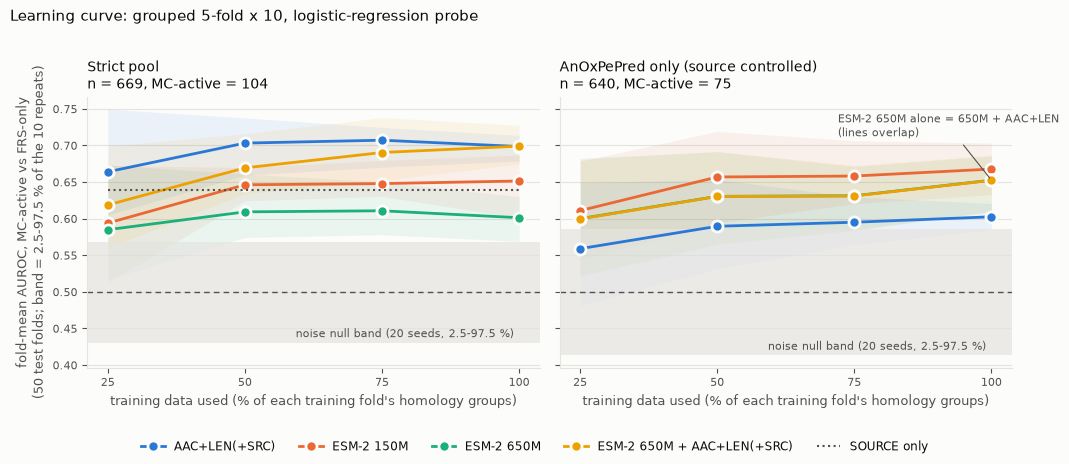

In [11]:
# Static figure (PNG): two small multiples on one shared y-scale; categorical slots 1-4 in fixed order, colour follows the feature set.
C = {"AAC+LEN(+SRC)": "#2a78d6", "ESM-2 150M": "#eb6834", "ESM-2 650M": "#1baf7a", "ESM-2 650M + AAC+LEN(+SRC)": "#eda100"}
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
KEY = {"AAC+LEN+SRC": "AAC+LEN(+SRC)", "AAC+LEN": "AAC+LEN(+SRC)", "ESM-2 150M": "ESM-2 150M", "ESM-2 650M": "ESM-2 650M",
       "ESM-2 650M + AAC+LEN+SRC": "ESM-2 650M + AAC+LEN(+SRC)", "ESM-2 650M + AAC+LEN": "ESM-2 650M + AAC+LEN(+SRC)"}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True, facecolor=SURF)
for ax, pool in zip(axes, ["strict", "strict, AnOxPePred only"]):
    ax.set_facecolor(SURF)
    sub = LC[LC.pool == pool].copy(); sub["key"] = sub.features.map(KEY)
    for key, col in C.items():
        s = sub[sub.key == key].sort_values("train_frac")
        if s.empty: continue
        x = s.train_frac * 100
        ax.fill_between(x, s.AUROC_rep_p2_5, s.AUROC_rep_p97_5, color=col, alpha=0.08, lw=0)
        ax.plot(x, s.AUROC, color=col, lw=2, marker="o", ms=8, mec=SURF, mew=2, label=key)
    nb_ = NULL_S if pool == "strict" else NULL_A
    ax.axhspan(nb_["lo"], nb_["hi"], color=GRID, alpha=0.7, lw=0)
    ax.axhline(0.5, color=INK2, lw=1, ls=(0, (4, 3)))
    ax.text(99, nb_["lo"] + 0.004, "noise null band (20 seeds, 2.5-97.5 %)", color=INK2, fontsize=8, va="bottom", ha="right")
    if pool != "strict":
        e = sub[sub.features == "ESM-2 650M"].sort_values("train_frac").iloc[-1]
        ax.annotate("ESM-2 650M alone = 650M + AAC+LEN\n(lines overlap)", xy=(100, e.AUROC), xytext=(72, e.AUROC + 0.06),
                    color=INK2, fontsize=8, arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8))
    if pool == "strict":
        src = sub[sub.features == "SOURCE"].sort_values("train_frac")
        ax.plot(src.train_frac * 100, src.AUROC, color=INK2, lw=1.5, ls=":", label="SOURCE only")
    n_mc = int(sub.n_MC.iloc[0]); n = int(sub.n.iloc[0])
    ax.set_title(f"{'Strict pool' if pool == 'strict' else 'AnOxPePred only (source controlled)'}\nn = {n}, MC-active = {n_mc}",
                 color=INK, fontsize=10, loc="left")
    ax.set_xticks([25, 50, 75, 100]); ax.set_xlabel("training data used (% of each training fold's homology groups)", color=INK2, fontsize=9)
    ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
    for sp_ in ("top", "right"): ax.spines[sp_].set_visible(False)
    for sp_ in ("left", "bottom"): ax.spines[sp_].set_color(GRID)
    ax.tick_params(colors=INK2, labelsize=8)
axes[0].set_ylabel("fold-mean AUROC, MC-active vs FRS-only\n(50 test folds; band = 2.5-97.5 % of the 10 repeats)", color=INK2, fontsize=9)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=5, frameon=False, fontsize=8.5, labelcolor=INK)
fig.suptitle("Learning curve: grouped 5-fold x 10, logistic-regression probe", color=INK, fontsize=11, x=0.01, ha="left")
fig.tight_layout(rect=(0, 0.08, 1, 0.97))
fig.savefig(f"{OUT}/step8_learning_curve.png", dpi=160, facecolor=SURF)
plt.show()

## 8. ΔAUROC of ESM-2 on top of the confounds (assessment item 1d)

In [12]:
S_ = (y_all, SPLITS, W_S, OOF_S, FA_S); A_ = (yA, SPLITS_A, W_A, OOF_A, FA_A)
rows = []
for sc in SCALES:
    rows.append(paired_delta(f"ESM-2 {sc} + AAC+LEN+SRC", "AAC+LEN+SRC", *S_, "strict: ESM-2 added to AAC+LEN+SRC"))
    rows.append(paired_delta(f"ESM-2 {sc}", "AAC+LEN+SRC", *S_, "strict: ESM-2 alone vs AAC+LEN+SRC"))
    rows.append(paired_delta(f"ESM-2 {sc} + AAC+LEN", "AAC+LEN", *A_, "AnOxPePred only: ESM-2 added to AAC+LEN"))
    rows.append(paired_delta(f"ESM-2 {sc}", "AAC-20", *A_, "AnOxPePred only: ESM-2 alone vs AAC-20"))
for a, b in (("SOURCE", "RANDOM noise"), ("LENGTH", "RANDOM noise"), ("AAC-20", "RANDOM noise"), ("AAC+LEN+SRC", "AAC+LEN"),
             ("ESM-2 650M", "SOURCE"), ("ESM-2 650M", "AAC-20"), ("ESM-2 650M", "RANDOM noise")):
    rows.append(paired_delta(a, b, *S_, "strict: confound checks"))
for a, b in (("LENGTH", "RANDOM noise"), ("AAC-20", "RANDOM noise"), ("AAC+LEN", "RANDOM noise"), ("ESM-2 650M", "RANDOM noise"), ("ESM-2 150M", "RANDOM noise")):
    rows.append(paired_delta(a, b, *A_, "AnOxPePred only: confound checks"))
DL = pd.DataFrame(rows); DL.to_csv(f"{OUT}/step8_delta_esm_over_confounds.csv", index=False)
print(DL[["context", "model", "reference", "AUROC_model", "AUROC_reference", "delta_AUROC", "lo", "hi", "p_boot_two_sided", "repeats_delta_gt_0", "verdict"]].round(3).to_string(index=False))

                                context                    model    reference  AUROC_model  AUROC_reference  delta_AUROC     lo     hi  p_boot_two_sided  repeats_delta_gt_0                verdict
     strict: ESM-2 added to AAC+LEN+SRC  ESM-2 35M + AAC+LEN+SRC  AAC+LEN+SRC        0.729            0.699        0.031 -0.044  0.062             0.493                  10 no difference detected
     strict: ESM-2 alone vs AAC+LEN+SRC                ESM-2 35M  AAC+LEN+SRC        0.605            0.699       -0.094 -0.186 -0.033             0.002                   0       reference better
AnOxPePred only: ESM-2 added to AAC+LEN      ESM-2 35M + AAC+LEN      AAC+LEN        0.679            0.603        0.076 -0.017  0.120             0.125                  10 no difference detected
 AnOxPePred only: ESM-2 alone vs AAC-20                ESM-2 35M       AAC-20        0.678            0.603        0.075 -0.027  0.120             0.199                  10 no difference detected
     strict: ESM-2 a

## 9. Headline table and metadata

In [13]:
def pick(df, name): r = df[df.features == name].iloc[0]; return f"{r.AUROC:.3f} [{r.lo:.3f}, {r.hi:.3f}]"
head = [{"question": "SOURCE only (strict)", "result": pick(PS, "SOURCE")},
        {"question": "LENGTH only (strict)", "result": pick(PS, "LENGTH")},
        {"question": "AAC-20 (strict)", "result": pick(PS, "AAC-20")},
        {"question": "AAC+LEN+SRC (strict)", "result": pick(PS, "AAC+LEN+SRC")},
        {"question": "ESM-2 650M (strict)", "result": pick(PS, "ESM-2 650M")},
        {"question": "ESM-2 150M (strict)", "result": pick(PS, "ESM-2 150M")},
        {"question": "RANDOM noise seed 0 (strict)", "result": pick(PS, "RANDOM noise (seed 0, as Step 5)")},
        {"question": "NULL band, 20 noise seeds (strict): mean [2.5 %, 97.5 %]", "result": pick(PS, NULL_S["features"])},
        {"question": "ESM-2 650M (AnOxPePred only)", "result": pick(PA, "ESM-2 650M")},
        {"question": "ESM-2 150M (AnOxPePred only)", "result": pick(PA, "ESM-2 150M")},
        {"question": "AAC+LEN (AnOxPePred only)", "result": pick(PA, "AAC+LEN")},
        {"question": "NULL band, 20 noise seeds (AnOxPePred only)", "result": pick(PA, NULL_A["features"])}]
for _, r in DL[DL.model.str.contains(r"\+") & DL.model.str.startswith("ESM-2")].iterrows():
    head.append({"question": f"dAUROC {r.model} - {r.reference} ({r.context.split(':')[0]})", "result": f"{r.delta_AUROC:+.3f} [{r.lo:+.3f}, {r.hi:+.3f}] {r.verdict}"})
for _, r in LM[LM.features.isin(["LENGTH", "ESM-2 650M", "AAC+LEN", "AAC+LEN+SRC"]) | LM.features.str.startswith("DELTA")].iterrows():
    head.append({"question": f"length-matched {r.pool}: {r.features}", "result": f"{r.AUROC_mean:+.3f} (draws {r.AUROC_p2_5:+.3f} .. {r.AUROC_p97_5:+.3f})"})
HEAD = pd.DataFrame(head); HEAD.to_csv(f"{OUT}/step8_headline.csv", index=False)
print(HEAD.to_string(index=False))

META = {"step": 8, "date_run": datetime.datetime.now().isoformat(timespec="seconds"), "versions": VERSIONS, "s2_fingerprint": FP,
        "input_sha256": HASHES, "seed": SEED, "n_boot": N_BOOT, "cv": f"StratifiedGroupKFold({N_SPLITS}, shuffle=True) x {N_REPEATS}, groups=homology_group",
        "headline_metric": "fold-mean AUROC over 50 test folds", "bootstrap": "group bootstrap over homology groups (weighted, all folds recomputed)",
        "step5_released_oof_auroc_esm650M": auc_rel, "length_bins": BINS[:-1], "match_draws": N_MATCH_DRAWS,
        "lc_fracs": LC_FRACS, "outputs": sorted(f for f in os.listdir(OUT) if f.startswith("step8_"))}
json.dump(META, open(f"{OUT}/step8_meta.json", "w", encoding="utf-8"), indent=2)
print(json.dumps(META["outputs"], indent=1))

                                                                    question                                         result
                                                        SOURCE only (strict)                           0.640 [0.592, 0.701]
                                                        LENGTH only (strict)                           0.608 [0.556, 0.681]
                                                             AAC-20 (strict)                           0.606 [0.557, 0.735]
                                                        AAC+LEN+SRC (strict)                           0.699 [0.648, 0.825]
                                                         ESM-2 650M (strict)                           0.601 [0.549, 0.729]
                                                         ESM-2 150M (strict)                           0.652 [0.599, 0.752]
                                                RANDOM noise seed 0 (strict)                           0.386 [0.352, 0.457]
        

## 10. Summary

**Date:** 2026-10-18 · **Notebook:** `STEP08_Confound_Controls.ipynb` · **Data:** release `aop_procon_v1` (S2 fingerprint `47d9c2a2fff63eb1`, matches the SHA-256 MANIFEST)
**Pool:** strict, n = 669 (MC-active 104 / FRS-only 565) · **CV:** `StratifiedGroupKFold(5)` × 10 repeats, groups = `homology_group`
**Metric:** fold-mean AUROC (mean of 50 test folds). CI = group bootstrap over homology groups. **Chance reference** = NULL band from 20 noise seeds.

---

## 1. In short: is any mechanism signal left?

**No ESM-2-specific mechanism signal remains after the confound controls.** What remains is a weak **amino-acid composition** difference of AUROC ≈ 0.60, and in the single-source, length-matched set even that is close to the upper edge of the NULL band.

| Question | Answer (fold-mean AUROC) |
|---|---|
| Best model in the strict pool? | **AAC+LEN+SRC = 0.699**, i.e. composition + length + **source** together. ESM-2 650M alone reaches only 0.601. |
| Source alone? | **SOURCE = 0.640**, higher than ESM-2 650M (0.601), 3B (0.588) and 35M (0.605). |
| Adding ESM-2 to AAC+LEN+SRC? | 650M: **+0.001** [−0.040, +0.036]. 150M: +0.043 [−0.028, +0.078]. 3B: **−0.043** (worse). No CI excludes 0. |
| Source confound removed (AnOxPePred-only, 75 vs 565)? | ESM-2 650M 0.653, AAC+LEN 0.603. ΔAUROC = +0.050 [−0.007, +0.088], p = 0.09. Positive in 10 of 10 repeats, but not significant. |
| Length matched as well (AnOxPePred-only + length-matched)? | ESM-2 650M 0.584, AAC+LEN 0.597. **ΔAUROC = −0.013** (> 0 in only 5 of 20 draws). The earlier +0.05 **disappears**. |
| Does more data help? (learning curve) | Most curves are **flat after 50 %**. The AnOxPePred-only ESM-2 curve rises slightly from 75 → 100 % (0.631 → 0.653), but that is still inside the CI. |

👉 **What can be stated in the paper:** *"Under homology-grouped, repeated CV, the best mechanism predictor is a source + composition + length baseline (AUROC 0.70). ESM-2 adds nothing measurable on top of it (Δ ≤ +0.04, CIs include 0; 3B is worse). In a single-source, length-matched subset all representations fall to AUROC ≈ 0.58–0.62, i.e. a weak composition-level difference only."*

---

## 2. What the two confounds really are (correction of N-19)

- **Source:** all 565 FRS-only peptides come from AnOxPePred. All 29 external-literature peptides are MC-active. The exact AUROC of the SOURCE feature is **0.639**.
- **Length:** the statement *"MC 9.4 aa vs FRS 5.8 aa"* is **wrong** (N-21). In the strict pool the mean length is 5.86 (MC) vs 5.75 (FRS). The real confound is **tripeptides**: **42.8 %** of FRS-only peptides are tripeptides, but only **16.3 %** of MC-active peptides. Length-only AUROC = 0.608.
- After length matching (bins 3, 4, 5, 6, 7, 8, 9–10, 11–14, ≥15, FRS:MC = 2:1, tripeptide share 16.3 % in both groups) the LENGTH probe falls to **0.41**, so no length signal is left. (Values below 0.5 are the usual CV "anti-learning" bias of a balanced feature that carries no signal.)

---

## 3. Split design (assessment item 2)

| Design | MC-active / test fold | MC-only / test fold | ESM-2 650M AUROC |
|---|---|---|---|
| `lso_fold` 2-fold (Step 5 retrieval) | 49 / 55 | **0 / 18** | 0.649 / 0.675 |
| `GroupKFold(5)` (Step 5 probe) | 17–28 | 0–7 | released **0.593**; re-run gives 0.602 / 0.655 |
| **`StratifiedGroupKFold(5)` × 10** | **20–21** | 0–9 | 0.601 (repeats 0.568 – 0.631) |

- With the same recipe, a single `GroupKFold` split ranges from **0.593 to 0.655**, depending on the scikit-learn version and the group-id order (N-22). **Do not quote single-split numbers.** Use the repeated fold-mean of Step 8.
- The *pooled* OOF AUROC of Step 5 is biased by the per-fold intercepts (N-22). Example: the exact value for SOURCE is 0.639, but the pooled value lies between 0.55 and 0.67 depending on the split.
- The RANDOM-noise row of Step 5 (0.384) is **a single noise draw** (seed 0, ≈ 3 sd low). The NULL band over 20 noise seeds is: strict **0.512 [0.430, 0.568]**, AnOxPePred-only 0.505 [0.413, 0.585] (N-23).

---

## 4. Limitations (stated honestly)

- The group-bootstrap CIs keep the fitted models fixed and only resample the test peptides, so they are **narrower** than the true uncertainty. Read them together with the NULL band, the repeat range, and the number of repeats in which Δ > 0.
- The spread of the length-matched results is only FRS subsampling variability, not a full CI.
- MC-active n = 104 (AnOxPePred-only 75). This is too little power to detect ΔAUROC differences below 0.05.
- Labels are not verified at assay level (FRS `source_reported` 631). The composition signal may itself be an AnOxPePred curation artefact.

## 5. Outputs (`C1/STEP 08/`)

`step8_probe_strict.csv` · `step8_probe_anoxpepred_only.csv` · `step8_length_matched.csv` (+ `_runs`) · `step8_learning_curve.csv` + `.png` · `step8_delta_esm_over_confounds.csv` · `step8_cv_design.csv` · `step8_fold_composition.csv` · `step8_headline.csv` · `step8_meta.json`

**🎤 Viva:** *"After controlling for source, length (tripeptides) and homology, ESM-2 embeddings tell us nothing about mechanism beyond amino-acid composition. What remains is a weak composition signal of AUROC ≈ 0.6. That is a negative result, but it was tested rigorously and reported together with its controls."*


*(Same text as `STEP08_Summary.md`; written from the outputs above.)*
